# Heart Disease — EDA, training and inference walkthrough
Interactive companion to `scripts/eda.py`, `heart.train` and `heart.predict`. Run from the repo root (`jupyter notebook notebooks/`).

In [1]:
import sys, os
sys.path[:0] = [os.path.abspath('../src'), os.path.abspath('..')]
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from heart import config
from heart.data import load_clean, split_xy
df = load_clean(); df.shape

(303, 14)

In [2]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df.isna().sum()[lambda s: s > 0]

ca      4
thal    2
dtype: int64

In [4]:
df[config.TARGET].value_counts(normalize=True).round(3)

target
0    0.541
1    0.459
Name: proportion, dtype: float64

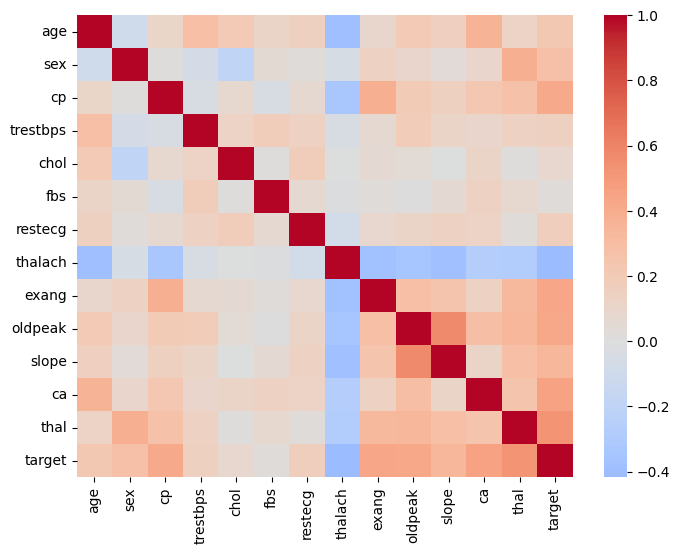

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df.corr(), cmap='coolwarm', center=0, ax=ax)
plt.show()

## Train (quick grid, no MLflow) and compare

In [6]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from heart.train import candidate_models, make_pipeline
X, y = split_xy(df)
cv = StratifiedKFold(5, shuffle=True, random_state=config.SEED)
for name, (est, _) in candidate_models().items():
    s = cross_val_score(make_pipeline(est), X, y, cv=cv, scoring='roc_auc')
    print(f'{name:22s} ROC-AUC {s.mean():.3f} ± {s.std():.3f}')

logistic_regression    ROC-AUC 0.915 ± 0.022


random_forest          ROC-AUC 0.904 ± 0.025


gradient_boosting      ROC-AUC 0.881 ± 0.020


## Inference with the saved model

In [7]:
from heart.predict import load_model, predict_records
model, meta = load_model(os.path.abspath('../models/model.joblib'))
print(meta['model_name'], meta['metrics']['test_roc_auc'])
predict_records([X.iloc[0].to_dict(), X.iloc[1].to_dict()], model=model)

logistic_regression 0.9589


[{'prediction': 0,
  'label': 'no_disease',
  'risk_probability': 0.2945,
  'confidence': 0.7055},
 {'prediction': 1,
  'label': 'disease',
  'risk_probability': 0.9957,
  'confidence': 0.9957}]